In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

In [2]:
# ============================================
# Imports (LATEST + COMPATIBLE)
# ============================================

import inspect
import math
import os
import abc
import warnings
from dataclasses import dataclass, field
from pathlib import Path
from typing import Any, Callable, Dict, List, Optional, Tuple, Union

import numpy as np
import torch
import torch.nn as nn
from torch.nn import functional as F
import torch.distributions as dist

import cv2
from PIL import Image
from IPython.display import display

from packaging import version

# 🔹 Transformers
from transformers import (
    CLIPTokenizer,
    CLIPTextModel,
    CLIPImageProcessor,
)

# 🔹 Diffusers
from diffusers.configuration_utils import FrozenDict
from diffusers.models import AutoencoderKL, UNet2DConditionModel
from diffusers.models.attention_processor import Attention
from diffusers.schedulers import KarrasDiffusionSchedulers
from diffusers.pipelines.pipeline_utils import DiffusionPipeline
from diffusers.pipelines.stable_diffusion import (
    StableDiffusionPipeline,
    StableDiffusionPipelineOutput,
)
from diffusers.pipelines.stable_diffusion.safety_checker import (
    StableDiffusionSafetyChecker,
)
from diffusers.utils import (
    deprecate,
    is_accelerate_available,
    logging,
)

# ✅ Replacement for removed randn_tensor
def randn_tensor(shape, device=None, dtype=None, generator=None):
    return torch.randn(
        shape,
        device=device,
        dtype=dtype,
        generator=generator,
    )

import pprint

warnings.filterwarnings("ignore", category=UserWarning)
logger = logging.get_logger(__name__)

print("✓ All imports successful!")
print(f"PyTorch: {torch.__version__}")
print(f"CUDA Available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"CUDA Device: {torch.cuda.get_device_name(0)}")


Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Flax classes are deprecated and will be removed in Diffusers v1.0.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.


✓ All imports successful!
PyTorch: 2.9.0+cu126
CUDA Available: True
CUDA Device: Tesla T4


In [3]:
@dataclass
class RunConfig:
    prompt: str
    neg_prompt: str = ""
    sd_2_1: bool = False
    token_indices: List[int] = field(default_factory=lambda: [1,2,3,4])
    seeds: List[int] = field(default_factory=lambda: [42])
    output_path: Path = Path('./outputs')
    n_inference_steps: int = 50
    guidance_scale: float = 7.5
    max_iter_to_alter: int = 25
    attention_res: int = 16
    run_standard_sd: bool = False
    run_attention_sd: bool = True
    thresholds: Dict[int, float] = field(default_factory=lambda: {0:0, 5:0, 10:0, 20:0})
    scale_factor: int = 20
    scale_range: tuple = field(default_factory=lambda: (1.0, 0.5))
    smooth_attentions: bool = True
    sigma: float = 0.5
    kernel_size: int = 3
    attention_corr_indices: List[List[int]] = field(default_factory=lambda: [])
    attention_leak_indices: List[List[int]] = field(default_factory=lambda: [])
    attention_exist_indices: List[int] = field(default_factory=lambda: [])
    attention_possession_indices: List[List[int]] = field(default_factory=lambda: [])
    loss_function: str = "attention_product_prob"

    def __post_init__(self):
        self.output_path.mkdir(exist_ok=True, parents=True)

print("✓ Config class created")


# ═══════════════════════════════════════════════════════════════
# CELL 4: Gaussian Smoothing
# ═══════════════════════════════════════════════════════════════
class GaussianSmoothing(nn.Module):
    def __init__(self, channels, kernel_size, sigma, dim=2):
        super(GaussianSmoothing, self).__init__()
        
        if isinstance(kernel_size, int):
            kernel_size = [kernel_size] * dim
        if isinstance(sigma, float):
            sigma = [sigma] * dim

        kernel = 1
        meshgrids = torch.meshgrid([torch.arange(size, dtype=torch.float32) for size in kernel_size], indexing='ij')
        
        for size, std, mgrid in zip(kernel_size, sigma, meshgrids):
            mean = (size - 1) / 2
            kernel *= 1 / (std * math.sqrt(2 * math.pi)) * torch.exp(-((mgrid - mean) / std) ** 2 / 2)

        kernel = kernel / torch.sum(kernel)
        kernel = kernel.view(1, 1, *kernel.size())
        kernel = kernel.repeat(channels, *[1] * (kernel.dim() - 1))

        self.register_buffer('weight', kernel)
        self.groups = channels
        self.conv = F.conv2d if dim == 2 else F.conv3d if dim == 3 else F.conv1d

    def forward(self, input):
        return self.conv(input, weight=self.weight, groups=self.groups)

print("✓ GaussianSmoothing created")


# ═══════════════════════════════════════════════════════════════
# CELL 5: Attention Processor
# ═══════════════════════════════════════════════════════════════
class AttendExciteCrossAttnProcessor:
    def __init__(self, attnstore, place_in_unet):
        super().__init__()
        self.attnstore = attnstore
        self.place_in_unet = place_in_unet

    def __call__(self, attn: Attention, hidden_states, encoder_hidden_states=None, attention_mask=None):
        batch_size, sequence_length, _ = hidden_states.shape
        attention_mask = attn.prepare_attention_mask(attention_mask, sequence_length, batch_size)

        query = attn.to_q(hidden_states)
        is_cross = encoder_hidden_states is not None
        encoder_hidden_states = encoder_hidden_states if is_cross else hidden_states
        key = attn.to_k(encoder_hidden_states)
        value = attn.to_v(encoder_hidden_states)

        query = attn.head_to_batch_dim(query)
        key = attn.head_to_batch_dim(key)
        value = attn.head_to_batch_dim(value)

        attention_probs = attn.get_attention_scores(query, key, attention_mask)
        self.attnstore(attention_probs, is_cross, self.place_in_unet)

        hidden_states = torch.bmm(attention_probs, value)
        hidden_states = attn.batch_to_head_dim(hidden_states)
        hidden_states = attn.to_out[0](hidden_states)
        hidden_states = attn.to_out[1](hidden_states)
        return hidden_states

def register_attention_control(model, controller):
    attn_procs = {}
    cross_att_count = 0
    for name in model.unet.attn_processors.keys():
        if name.startswith("mid_block"):
            place_in_unet = "mid"
        elif name.startswith("up_blocks"):
            place_in_unet = "up"
        elif name.startswith("down_blocks"):
            place_in_unet = "down"
        else:
            continue
        cross_att_count += 1
        attn_procs[name] = AttendExciteCrossAttnProcessor(attnstore=controller, place_in_unet=place_in_unet)
    
    model.unet.set_attn_processor(attn_procs)
    controller.num_att_layers = cross_att_count

print("✓ Attention processor created")


# ═══════════════════════════════════════════════════════════════
# CELL 6: Attention Store
# ═══════════════════════════════════════════════════════════════
class AttentionControl(abc.ABC):
    def __init__(self):
        self.cur_step = 0
        self.num_att_layers = -1
        self.cur_att_layer = 0

    @property
    def num_uncond_att_layers(self):
        return 0

    @abc.abstractmethod
    def forward(self, attn, is_cross: bool, place_in_unet: str):
        raise NotImplementedError

    def __call__(self, attn, is_cross: bool, place_in_unet: str):
        if self.cur_att_layer >= self.num_uncond_att_layers:
            self.forward(attn, is_cross, place_in_unet)
        self.cur_att_layer += 1
        if self.cur_att_layer == self.num_att_layers + self.num_uncond_att_layers:
            self.cur_att_layer = 0
            self.cur_step += 1
            self.between_steps()

    def between_steps(self):
        return

    def reset(self):
        self.cur_step = 0
        self.cur_att_layer = 0

class AttentionStore(AttentionControl):
    @staticmethod
    def get_empty_store():
        return {"down_cross": [], "mid_cross": [], "up_cross": [],
                "down_self": [], "mid_self": [], "up_self": []}

    def __init__(self, save_global_store=False):
        super().__init__()
        self.save_global_store = save_global_store
        self.step_store = self.get_empty_store()
        self.attention_store = {}
        self.global_store = {}

    def forward(self, attn, is_cross: bool, place_in_unet: str):
        key = f"{place_in_unet}_{'cross' if is_cross else 'self'}"
        if attn.shape[1] <= 32 ** 2:
            self.step_store[key].append(attn)
        return attn

    def between_steps(self):
        self.attention_store = self.step_store
        self.step_store = self.get_empty_store()

    def get_average_attention(self):
        return self.attention_store

    def reset(self):
        super().reset()
        self.step_store = self.get_empty_store()
        self.attention_store = {}
        self.global_store = {}

def aggregate_attention(attention_store: AttentionStore, res: int, 
                       from_where: List[str], is_cross: bool, select: int):
    out = []
    attention_maps = attention_store.get_average_attention()
    num_pixels = res ** 2
    for location in from_where:
        for item in attention_maps[f"{location}_{'cross' if is_cross else 'self'}"]:
            if item.shape[1] == num_pixels:
                cross_maps = item.reshape(1, -1, res, res, item.shape[-1])[select]
                out.append(cross_maps)
    if len(out) == 0:
        return torch.zeros(res, res, 77).to(attention_store.step_store["down_cross"][0].device)
    out = torch.cat(out, dim=0)
    out = out.sum(0) / out.shape[0]
    return out

print("✓ Attention store created")

print("\n" + "="*60)
print("Part 1 Complete! Now run Part 2 for the Pipeline")
print("="*60)


✓ Config class created
✓ GaussianSmoothing created
✓ Attention processor created
✓ Attention store created

Part 1 Complete! Now run Part 2 for the Pipeline


In [7]:
# ═══════════════════════════════════════════════════════════════
# PREDICATED DIFFUSION - PART 2 (FIXED FOR KAGGLE)
# Pipeline Implementation and Usage Examples
# RUN THIS AFTER PART 1
# ═══════════════════════════════════════════════════════════════

# ═══════════════════════════════════════════════════════════════
# CELL 7: Pipeline Class
# ═══════════════════════════════════════════════════════════════
class PredicatedDiffPipeline(StableDiffusionPipeline):
    
    def _encode_prompt(self, prompt, device, num_images_per_prompt, do_classifier_free_guidance, 
                       negative_prompt=None, prompt_embeds=None, negative_prompt_embeds=None):
        
        if prompt is not None and isinstance(prompt, str):
            batch_size = 1
        elif prompt is not None and isinstance(prompt, list):
            batch_size = len(prompt)
        else:
            batch_size = prompt_embeds.shape[0]

        if prompt_embeds is None:
            text_inputs = self.tokenizer(
                prompt, padding="max_length", max_length=self.tokenizer.model_max_length,
                truncation=True, return_tensors="pt")
            text_input_ids = text_inputs.input_ids

            prompt_embeds = self.text_encoder(text_input_ids.to(device))[0]

        prompt_embeds = prompt_embeds.to(dtype=self.text_encoder.dtype, device=device)
        bs_embed, seq_len, _ = prompt_embeds.shape
        prompt_embeds = prompt_embeds.repeat(1, num_images_per_prompt, 1)
        prompt_embeds = prompt_embeds.view(bs_embed * num_images_per_prompt, seq_len, -1)

        if do_classifier_free_guidance and negative_prompt_embeds is None:
            uncond_tokens = [""] * batch_size if negative_prompt is None else [negative_prompt] if isinstance(negative_prompt, str) else negative_prompt
            
            max_length = prompt_embeds.shape[1]
            uncond_input = self.tokenizer(uncond_tokens, padding="max_length", max_length=max_length, truncation=True, return_tensors="pt")
            negative_prompt_embeds = self.text_encoder(uncond_input.input_ids.to(device))[0]

        if do_classifier_free_guidance:
            seq_len = negative_prompt_embeds.shape[1]
            negative_prompt_embeds = negative_prompt_embeds.to(dtype=self.text_encoder.dtype, device=device)
            negative_prompt_embeds = negative_prompt_embeds.repeat(1, num_images_per_prompt, 1)
            negative_prompt_embeds = negative_prompt_embeds.view(batch_size * num_images_per_prompt, seq_len, -1)
            prompt_embeds = torch.cat([negative_prompt_embeds, prompt_embeds])

        return text_inputs, prompt_embeds

    def _aggregate_attention_per_token(self, attention_store, attention_res=16):
        attention_maps = aggregate_attention(
            attention_store=attention_store, res=attention_res,
            from_where=("up", "down", "mid"), is_cross=True, select=0)
        return attention_maps

    @staticmethod
    def _update_latent(latents, loss, step_size):
        grad_cond = torch.autograd.grad(loss.requires_grad_(True), [latents], retain_graph=True)[0]
        latents = latents - step_size * grad_cond
        return latents

    def _compute_loss_attention_product_prob(self, attention_maps, size, 
                                            attention_corr_indices,
                                            attention_leak_indices, 
                                            attention_exist_indices,
                                            attention_possession_indices):
        """
        FIXED: Correct parameter order - size comes AFTER attention_maps
        """
        loss = 0
        eps = 1e-20
        attention_for_obj = []
        
        last_idx = -1
        attention_normalize = attention_maps[:, :, 1:last_idx].clone()
        attention_normalize *= 100
        attention_normalize = torch.nn.functional.softmax(attention_normalize, dim=-1)

        # Exist loss
        if len(attention_exist_indices) > 0:
            for exist_ind in attention_exist_indices:
                atten_obj_exist = attention_normalize[:, :, exist_ind-1]
                loss_attend_value = torch.sum(torch.log(1 - atten_obj_exist + 1e-4)) / size
                loss_attend_value = -torch.log(1 - torch.exp(loss_attend_value) + eps)
                loss = loss + 0.1 * loss_attend_value / len(attention_exist_indices)

        # Correspondence loss
        if len(attention_corr_indices) > 0:
            for corr_ind in attention_corr_indices:
                atten_adj = attention_maps[:, :, corr_ind[0]]
                atten_obj = attention_maps[:, :, corr_ind[1]]
                atten_adj = (atten_adj - atten_adj.min()) / (atten_adj.max() - atten_adj.min() + eps)
                atten_obj = (atten_obj - atten_obj.min()) / (atten_obj.max() - atten_obj.min() + eps)
                attention_for_obj.append(atten_adj)
                attention_for_obj.append(atten_obj)
                
                loss_corr = -torch.log(1 - (atten_obj * (1 - atten_adj)) + eps) - torch.log(1 - (atten_adj * (1 - atten_obj)) + eps)
                loss_corr = torch.sum(loss_corr) / size
                loss = loss + loss_corr / len(attention_corr_indices)

        # Leak loss
        if len(attention_leak_indices) > 0:
            for leak_ind in attention_leak_indices:
                atten_adj = attention_maps[:, :, leak_ind[0]]
                atten_obj = attention_maps[:, :, leak_ind[1]]
                atten_adj = (atten_adj - atten_adj.min()) / (atten_adj.max() - atten_adj.min() + eps)
                atten_obj = (atten_obj - atten_obj.min()) / (atten_obj.max() - atten_obj.min() + eps)
                
                loss_leak = -torch.log(1 - (atten_obj * atten_adj) + eps)
                loss_leak = torch.sum(loss_leak) / size
                loss = loss + 0.3 * loss_leak / len(attention_leak_indices)

        # Possession loss
        if len(attention_possession_indices) > 0:
            for possession_ind in attention_possession_indices:
                atten_holder = attention_maps[:, :, possession_ind[0]]
                atten_possession = attention_maps[:, :, possession_ind[1]]
                atten_possession = (atten_possession - atten_possession.min()) / (atten_possession.max() - atten_possession.min() + eps)
                atten_holder = (atten_holder - atten_holder.min()) / (atten_holder.max() - atten_holder.min() + eps)
                attention_for_obj.append(atten_possession)
                attention_for_obj.append(atten_holder)
                
                loss_poss = -torch.log(1 - (atten_possession * (1 - atten_holder)) + eps)
                loss_poss = torch.sum(loss_poss) / size
                loss = loss + loss_poss / len(attention_possession_indices)

        return loss, attention_for_obj

    def _perform_iterative_refinement(self, latents, loss, threshold, text_embeddings, 
                                     attention_corr_indices, attention_leak_indices, 
                                     attention_exist_indices, attention_possession_indices, 
                                     attention_store, step_size, t, attention_res=16):
        
        attention_size = 256
        
        for iteration in range(5):
            latents = latents.clone().detach().requires_grad_(True)
            _ = self.unet(latents, t, encoder_hidden_states=text_embeddings[1].unsqueeze(0)).sample
            self.unet.zero_grad()

            attention_maps = self._aggregate_attention_per_token(attention_store, attention_res)
            
            # FIXED: Correct parameter order
            loss, _ = self._compute_loss_attention_product_prob(
                attention_maps, attention_size,
                attention_corr_indices, attention_leak_indices, 
                attention_exist_indices, attention_possession_indices)

            if loss != 0:
                latents = self._update_latent(latents, loss, step_size)

        return loss, latents

    @torch.no_grad()
    def __call__(self, prompt, neg_prompt, attention_store, indices_to_alter, 
                 attention_res=16, height=None, width=None, num_inference_steps=50, 
                 guidance_scale=7.5, negative_prompt=None, num_images_per_prompt=1, 
                 generator=None, latents=None, max_iter_to_alter=25, 
                 run_attention_sd=True, thresholds=None, scale_factor=20, 
                 scale_range=(1., 0.5), attention_corr_indices=None, 
                 attention_leak_indices=None, attention_exist_indices=None, 
                 attention_possession_indices=None, **kwargs):

        if thresholds is None:
            thresholds = {}
        if attention_corr_indices is None:
            attention_corr_indices = []
        if attention_leak_indices is None:
            attention_leak_indices = []
        if attention_exist_indices is None:
            attention_exist_indices = []
        if attention_possession_indices is None:
            attention_possession_indices = []
        
        height = height or self.unet.config.sample_size * self.vae_scale_factor
        width = width or self.unet.config.sample_size * self.vae_scale_factor
        device = self._execution_device
        do_classifier_free_guidance = guidance_scale > 1.0

        text_inputs, prompt_embeds = self._encode_prompt(
            prompt, device, num_images_per_prompt, do_classifier_free_guidance, negative_prompt)

        self.scheduler.set_timesteps(num_inference_steps, device=device)
        timesteps = self.scheduler.timesteps

        num_channels_latents = self.unet.config.in_channels
        latents = self.prepare_latents(
            1 * num_images_per_prompt, num_channels_latents, height, width,
            prompt_embeds.dtype, device, generator, latents)

        extra_step_kwargs = self.prepare_extra_step_kwargs(generator, 0.0)
        scale_range_arr = np.linspace(scale_range[0], scale_range[1], len(timesteps))
        
        attention_size = 256
        loss_values = []

        for i, t in enumerate(timesteps):
            with torch.enable_grad():
                latents = latents.clone().detach().requires_grad_(True)
                _ = self.unet(latents, t, encoder_hidden_states=prompt_embeds[1].unsqueeze(0)).sample
                self.unet.zero_grad()

                attention_maps = self._aggregate_attention_per_token(attention_store, attention_res)

                if run_attention_sd:
                    # FIXED: Correct parameter order
                    loss, _ = self._compute_loss_attention_product_prob(
                        attention_maps, attention_size,
                        attention_corr_indices, attention_leak_indices,
                        attention_exist_indices, attention_possession_indices)

                    if i < max_iter_to_alter and loss != 0:
                        latents = self._update_latent(
                            latents, loss, scale_factor * np.sqrt(scale_range_arr[i]))

                    if i in thresholds.keys():
                        loss, latents = self._perform_iterative_refinement(
                            latents, loss, thresholds[i], prompt_embeds, 
                            attention_corr_indices, attention_leak_indices,
                            attention_exist_indices, attention_possession_indices,
                            attention_store, scale_factor * np.sqrt(scale_range_arr[i]), t, attention_res)

                    loss_values.append(loss.detach().cpu().item() if isinstance(loss, torch.Tensor) else 0)

            latent_model_input = torch.cat([latents] * 2) if do_classifier_free_guidance else latents
            latent_model_input = self.scheduler.scale_model_input(latent_model_input, t)

            noise_pred = self.unet(latent_model_input, t, encoder_hidden_states=prompt_embeds).sample
            self.unet.zero_grad()

            if do_classifier_free_guidance:
                noise_pred_uncond, noise_pred_text = noise_pred.chunk(2)
                noise_pred = noise_pred_uncond + guidance_scale * (noise_pred_text - noise_pred_uncond)

            latents = self.scheduler.step(noise_pred, t, latents, **extra_step_kwargs).prev_sample

        image = self.decode_latents(latents)
        image = self.numpy_to_pil(image)

        return StableDiffusionPipelineOutput(images=image, nsfw_content_detected=[False]), loss_values

print("✓ Pipeline class created")


# ═══════════════════════════════════════════════════════════════
# CELL 8: Helper Functions
# ═══════════════════════════════════════════════════════════════
def load_model(sd_2_1=False):
    device = torch.device('cuda:0') if torch.cuda.is_available() else torch.device('cpu')
    model_id = "stabilityai/stable-diffusion-2-1-base" if sd_2_1 else "CompVis/stable-diffusion-v1-4"
    
    print(f"Loading model: {model_id}")
    stable = PredicatedDiffPipeline.from_pretrained(model_id).to(device)
    stable.safety_checker = None
    
    print("✓ Model loaded successfully!")
    return stable

def find_token_indices(stable, prompt: str):
    tokens = stable.tokenizer.encode(prompt)
    print(f"\nPrompt: '{prompt}'")
    print("\nToken mapping:")
    for idx, t in enumerate(tokens):
        word = stable.tokenizer.decode([t])
        print(f"  Index {idx}: '{word}'")
    return tokens

print("✓ Helper functions created")


# ═══════════════════════════════════════════════════════════════
# CELL 9: Run Function
# ═══════════════════════════════════════════════════════════════
def run_on_prompt(prompt, model, controller, token_indices, seed, config,negative_prompt):
    register_attention_control(model, controller)
    generator = torch.Generator(model.device).manual_seed(seed)
    
    outputs, loss_values = model(
        prompt=prompt,
        neg_prompt=config.neg_prompt,
        attention_store=controller,
        indices_to_alter=token_indices,
        attention_res=config.attention_res,
        guidance_scale=config.guidance_scale,
        generator=generator,
        num_inference_steps=config.n_inference_steps,
        max_iter_to_alter=config.max_iter_to_alter,
        run_attention_sd=config.run_attention_sd,
        thresholds=config.thresholds,
        scale_factor=config.scale_factor,
        scale_range=config.scale_range,
        attention_corr_indices=config.attention_corr_indices,
        attention_leak_indices=config.attention_leak_indices,
        attention_exist_indices=config.attention_exist_indices,
        attention_possession_indices=config.attention_possession_indices,
    )
    
    return outputs.images[0], loss_values

print("✓ Run function created")


# ═══════════════════════════════════════════════════════════════
# CELL 10: Load Model (RUN THIS - Takes 1-2 minutes)
# ═══════════════════════════════════════════════════════════════
print("Loading model...")
stable = load_model(sd_2_1=False)
print("\n✓ Model ready to use!")



✓ Pipeline class created
✓ Helper functions created
✓ Run function created
Loading model...
Loading model: CompVis/stable-diffusion-v1-4


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

StableDiffusionSafetyChecker LOAD REPORT from: /root/.cache/huggingface/hub/models--CompVis--stable-diffusion-v1-4/snapshots/133a221b8aa7292a167afc5127cb63fb5005638b/safety_checker
Key                                               | Status     |  | 
--------------------------------------------------+------------+--+-
vision_model.vision_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

CLIPTextModel LOAD REPORT from: /root/.cache/huggingface/hub/models--CompVis--stable-diffusion-v1-4/snapshots/133a221b8aa7292a167afc5127cb63fb5005638b/text_encoder
Key                                | Status     |  | 
-----------------------------------+------------+--+-
text_model.embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


✓ Model loaded successfully!

✓ Model ready to use!


In [8]:

# ═══════════════════════════════════════════════════════════════
# CELL 11: Example 1 - Color Binding (Red Cat, White Dog)
# # ═══════════════════════════════════════════════════════════════
# prompt = "A yellow car and a blue bird."
# find_token_indices(stable, prompt)

# config = RunConfig(
#     prompt="A yellow car and a blue bird.",
#     seeds=[500],
#     n_inference_steps=50,
#     guidance_scale=7.5,
#     attention_corr_indices=[[2,3], [6,7]],  # red→cat, white→dog
#     attention_leak_indices=[[2,7], [6,3]],  # prevent red→dog, white→cat
#     attention_exist_indices=[3, 7],         # ensure cat and dog exist
#     max_iter_to_alter=25,
#     thresholds={0:0, 5:0, 10:0, 20:0},
#     scale_factor=20
# )



# controller = AttentionStore()
# image, loss_values = run_on_prompt(
#     prompt=config.prompt,
#     model=stable,
#     controller=controller,
#     token_indices=[3, 7],
#     seed=42,
#     config=config
# )

# output_dir = config.output_path / 'results'
# output_dir.mkdir(exist_ok=True, parents=True)
# image.save(output_dir / 'red_cat_white_dog.png')
# display(image)
# print(f"✓ Saved to: {output_dir / 'red_cat_white_dog.png'}")


# ═══════════════════════════════════════════════════════════════
# CELL 12: Custom Generation Function
# ═══════════════════════════════════════════════════════════════
def generate_custom(prompt, corr_indices, leak_indices, exist_indices, 
                    possession_indices=[], seed=42, steps=50,negative_prompt=None):
    """
    Easy function to generate custom prompts
    
    Args:
        prompt: Your text prompt
        corr_indices: [[adj1, noun1], [adj2, noun2]] - bind attributes
        leak_indices: [[adj1, noun2], [adj2, noun1]] - prevent cross-binding
        exist_indices: [noun1, noun2] - ensure objects exist
        possession_indices: [[holder, possession]] - for "X with Y"
        seed: Random seed
        steps: Number of steps
    """
    
    print("\n" + "="*60)
    print(f"Prompt: {prompt}")
    print("="*60)
    find_token_indices(stable, prompt)
    
    config = RunConfig(
        prompt=prompt,
        seeds=[seed],
        n_inference_steps=steps,
        attention_corr_indices=corr_indices,
        attention_leak_indices=leak_indices,
        attention_exist_indices=exist_indices,
        attention_possession_indices=possession_indices,
        run_attention_sd=True,
        thresholds={0:0, 5:0, 10:0, 20:0}
    )
    
    print(f"\nGenerating with seed {seed}...")
    controller = AttentionStore()
    image, _ = run_on_prompt(
        prompt=prompt,
        model=stable,
        controller=controller,
        token_indices=exist_indices,
        seed=seed,
        config=config,
        negative_prompt=negative_prompt
    )
    
    output_dir = config.output_path / 'results'
    output_dir.mkdir(exist_ok=True, parents=True)
    safe_name = prompt.replace(" ", "_")[:50]
    image.save(output_dir / f'{safe_name}.png')
    display(image)
    
    print(f"✓ Saved to: {output_dir / f'{safe_name}.png'}")
    return image

print("✓ Custom generation function ready!")


✓ Custom generation function ready!



🚀 Processing Prompt 1/1: A ball roughly next to a basket
Generating Seed: 142...
Prompt: A ball roughly next to a basket

Prompt: 'A ball roughly next to a basket'

Token mapping:
  Index 0: '<|startoftext|>'
  Index 1: 'a'
  Index 2: 'ball'
  Index 3: 'roughly'
  Index 4: 'next'
  Index 5: 'to'
  Index 6: 'a'
  Index 7: 'basket'
  Index 8: '<|endoftext|>'

Generating with seed 142...


/usr/local/lib/python3.12/dist-packages/diffusers/pipelines/stable_diffusion/pipeline_stable_diffusion.py:599: FutureWarning: The decode_latents method is deprecated and will be removed in 1.0.0. Please use VaeImageProcessor.postprocess(...) instead
  deprecate("decode_latents", "1.0.0", deprecation_message, standard_warn=False)


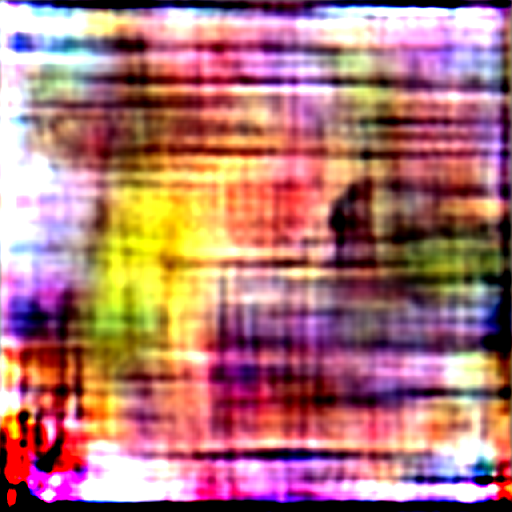

✓ Saved to: outputs/results/A_ball_roughly_next_to_a_basket.png
Generating Seed: 742...
Prompt: A ball roughly next to a basket

Prompt: 'A ball roughly next to a basket'

Token mapping:
  Index 0: '<|startoftext|>'
  Index 1: 'a'
  Index 2: 'ball'
  Index 3: 'roughly'
  Index 4: 'next'
  Index 5: 'to'
  Index 6: 'a'
  Index 7: 'basket'
  Index 8: '<|endoftext|>'

Generating with seed 742...


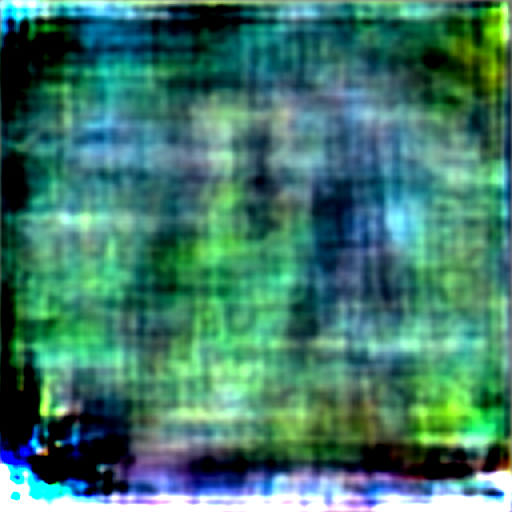

✓ Saved to: outputs/results/A_ball_roughly_next_to_a_basket.png
Generating Seed: 842...
Prompt: A ball roughly next to a basket

Prompt: 'A ball roughly next to a basket'

Token mapping:
  Index 0: '<|startoftext|>'
  Index 1: 'a'
  Index 2: 'ball'
  Index 3: 'roughly'
  Index 4: 'next'
  Index 5: 'to'
  Index 6: 'a'
  Index 7: 'basket'
  Index 8: '<|endoftext|>'

Generating with seed 842...


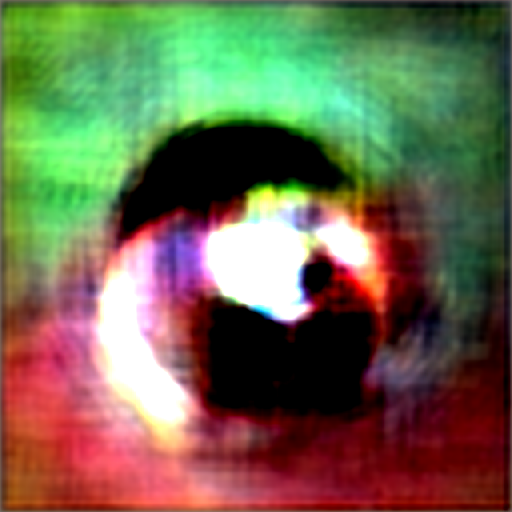

✓ Saved to: outputs/results/A_ball_roughly_next_to_a_basket.png

✨ Batch complete. All images saved in: /kaggle/working/predicate_Batch


In [9]:
import os
import torch
from pathlib import Path
from IPython.display import display
from diffusers import StableDiffusionXLImg2ImgPipeline

# ===============================
# ENTRY POINT
# ===============================
if __name__ == "__main__":

    corr_indices = [[1,2], [5,6]]     # black→dog, white→cat
    # prevent leakage (wrong binding)
    leak_indices = [[1,6], [5,2]]     # black→cat, white→dog
    # ensure objects exist
    exist_indices = [2,6]  
    # List of prompts to evaluate for compositional logic
    prompts = [
            "A ball roughly next to a basket"
    ]
    
    # Note: Ensure get_token_indices extracts the correct nouns for each prompt
    # Here we define the tracking words per prompt index
    tracking_words = [
        ["ball", "basket"]
    ]

    negative_prompt = (
        "same size object, equal size, merged objects, "
        "single subject, blurry, low quality, cartoon, illustration, "
        "3d render, painting, text, watermark"
    )

    # Generate seeds from 42 to 142 inclusive (101 total)
    seeds = [142,742,842]


    output_root = Path("./predicate_Batch")
    output_root.mkdir(exist_ok=True)

    for p_idx, prompt_text in enumerate(prompts):
        # Create a subfolder for each specific prompt to avoid clutter
        prompt_folder_name = prompt_text[:30].replace(" ", "_")
        prompt_path = output_root / f"prompt_{p_idx}_{prompt_folder_name}"
        prompt_path.mkdir(exist_ok=True)
        
        words = tracking_words[p_idx]

        print(f"\n🚀 Processing Prompt {p_idx+1}/{len(prompts)}: {prompt_text}")

        for seed_value in seeds:
            print(f"Generating Seed: {seed_value}...", end="\r")

            # ===============================
            # Stage 1 — FUZZY GENERATION
            # ===============================
            image = generate_custom(
                prompt=prompt_text,
                corr_indices=corr_indices,
                leak_indices=leak_indices,
                exist_indices=exist_indices,
                seed=seed_value,
                steps=50,
                negative_prompt=negative_prompt
            )

            if image is None:
                continue

            # Save Stage-1 image
            s1_filename = f"seed_{seed_value}_stage1.png"
            image.save(prompt_path / s1_filename)


    print(f"\n✨ Batch complete. All images saved in: {output_root.absolute()}")